## Simplify model
- Use assumptions to simplify the analysis (e.g., plane sections remain plane, small deformations, etc.)
- Define the beam geometry and material properties
- Define the cross section properties (area, moment of inertia, etc.)
- Choose end conditions and loading conditions
- Choose if it's euler beam theory or Timoshenko beam theory

In [ ]:
import sys
sys.path.append('..')  # Goes up one level to the workspace root

from utils.Appendix.unit_convertors import *
from utils.Appendix.materials import * # import materials library

from utils.Appendix.structural.FBD_beams import * # create free body diagrams for beams
from utils.Appendix.structural.members import * # import beams library

beam_shape = I_beam(flange_width=0.2, flange_thickness=0.02, web_height=0.3, web_thickness=0.01)
beam_material = get_material("Steel")
beam = beam(material=beam_material, length=2.0, shape=beam_shape)
mass = beam.get_mass()
print(f"Mass of the beam: {mass:.2f} kg")
print(f"Cross-sectional Area: {beam.shape.area:.6e} m^2")
print(f"MoI_yy: {beam.shape.Iy:.6e} m^4")
print(f"MoI_zz: {beam.shape.Iz:.6e} m^4")

Mass of the beam: 172.70 kg
Cross-sectional Area: 1.100000e-02 m^2
MoI_yy: 2.669167e-05 m^4
MoI_zz: 2.698333e-05 m^4


Create Free Body Diagrams (FBDs) for beams to visualize the forces and moments acting on the structure. This will help in understanding the behavior of the beam under different loading conditions and end supports.

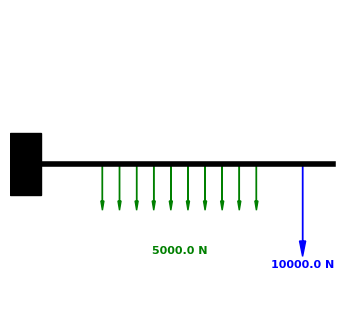

In [2]:
# 2. End conditions
set_end_conditions(beam, left=Fixed(), right=Free())

# 3. Loads
add_distributed_load(beam, w=5000, x1=0.5, x2=1.5)
add_point_load(beam, P=10000, x=1.8)
# add_moment_load(beam, M=2000, x=0.5)

plot_fbd(beam)
    

## Solve the problem using the appropriate method 
- Check static determinacy and choose the method accordingly (force method, slope-deflection method, Ritz method, finite element method)
- Calculate the internal forces (shear, moment) and deflections at different points along the beam
- Plot the shear force, bending moment, and deflection diagrams to visualize the results
- Check the results against the material and geometric properties to ensure that the beam can safely carry the applied loads without failure.

Decision table for static determinacy:

| Reactions (r) | Equilibrium Equations (m) | Determinacy Status                          | Method to Solve                            |
|---------------|--------------------------|---------------------------------------------|---------------------------------------------|
| r = m         | m = 3                    | Statically determinate                      | Use equilibrium equations (ΣFy = 0, ΣM = 0) |
| r < m         | m = 3                    | Statically indeterminate (underconstrained) | Use force method or slope-deflection method |
| r > m         | m = 3                    | Statically indeterminate (overconstrained)  | Use finite element method or Ritz method    |

In [3]:
#check static determinacy
method = 1
if static_determinacy(beam) != 0:
    method = 2  # FEM
    print("Beam is statically indeterminate. FEM recommended.")
else:
    print("Beam is statically determinate. Force balance can be used.")

print (static_determinacy(beam))

Beam is statically determinate. Force balance can be used.
0


Import the appropriate solvers.

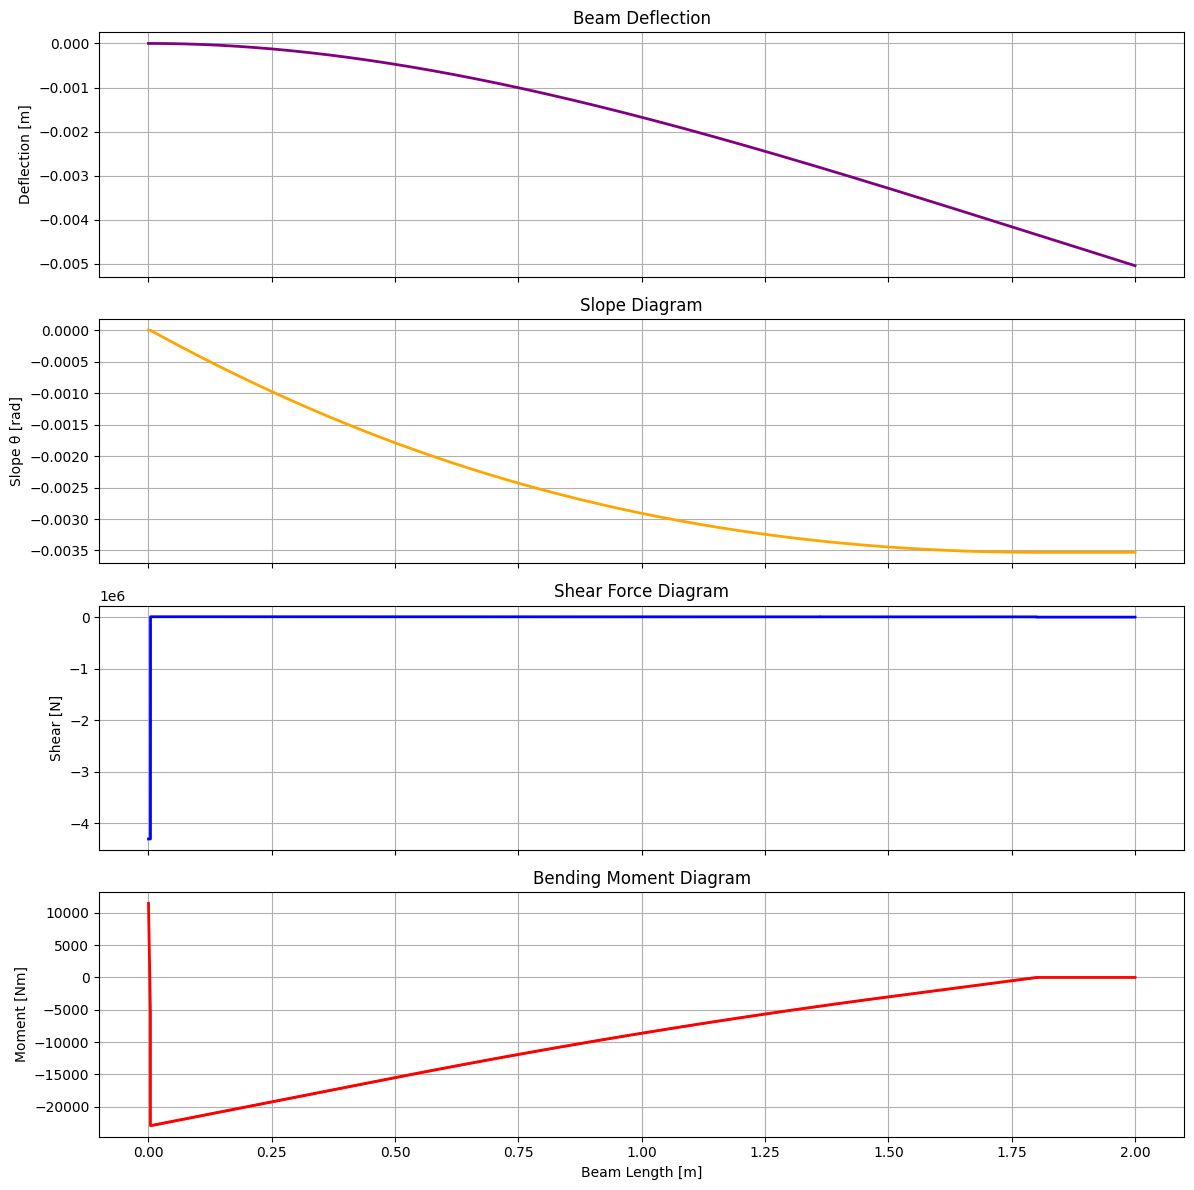

In [4]:
from solvers import DeterminateSolver, FEMSolver

# solver = DeterminateSolver(beam)
# print (solver.reactions())
# solver.plot()

solver = FEMSolver(beam, 500, theory="EB")
solver.solve()
solver.plot_results()